In [1]:
# Notebook 03 — Multiscale volatility
#
# Objective:
# - Measure recent EURUSD movement over 30 seconds, 1, 5 and 15 minutes.
# - Update every ten seconds.
# - Save RMS movement and centred population standard deviation.
# - Save the RMS one-minute/fifteen-minute ratio.
# - Save the largest change's share of squared movement.
#
# Input:
# - Notebook 02's all-hours ten-second sampled mid-price table.
# - Source run: sampling_02_v1.
#
# Calculations:
# - Ten-second change = (current mid - previous mid) / 0.0001.
# - RMS = square root of the mean squared change.
# - Population SD removes the window's average change and divides by N.
# - Shock share = largest squared change / sum of squared changes.
# - RMS ratio = RMS over 1 minute / RMS over 15 minutes.
#
# Lookbacks:
# - 30 seconds: 3 changes, requiring 4 prices.
# - 1 minute: 6 changes, requiring 7 prices.
# - 5 minutes: 30 changes, requiring 31 prices.
# - 15 minutes: 90 changes, requiring 91 prices.
#
# Continuity:
# - Require a full window of consecutive valid changes.
# - Never connect prices across an unfilled missing period.
# - Restart the lookback after a disruption or weekend closure.
# - Continue through excluded hours when prices remain available.
# - Keep project-exclusion flags separately.
# - Retain eligible interpolation, locked quotes and zero-size observations.
# - Sizes do not enter these calculations.
#
# Timing:
# - Preserve the source's full available_ns field.
# - One conservative publication timestamp covers all four windows.
# - It includes the availability of the preceding 91 sampled prices.
# - Short lookbacks can become ready before longer lookbacks.
# - Publication delay is not feature age at a later trading decision.
#
# Missing values:
# - Missing prices do not become zero changes.
# - Incomplete windows have missing measurements.
# - A valid flat window has RMS=0 and SD=0.
# - Shock share is missing when squared movement is zero.
# - The fast/slow ratio is missing when its denominator is zero.
# - No rounding, clipping or numerical floor changes the measurements.
#
# Units:
# - RMS and SD: pips of ten-second price change.
# - Ratio, shock share and interpolation fraction: dimensionless.
# - Stored timestamps: UTC Unix nanoseconds.
# - Display timezone: Europe/Athens.
#
# Interpretation:
# - These are historical measurements, not forecasts.
# - No high/low regime thresholds are fitted.
# - No limit-order, position-sizing or execution rule is implemented.
# - Forecast-informed limit exits remain a provisional later application.
#
# Outputs:
# - outputs/features/volatility/<RUN_ID>/YYYY-MM.parquet
# - reports/tables/volatility/<RUN_ID>/
# - reports/figures/volatility/<RUN_ID>/
#
# Processing:
# - Process bounded monthly inputs.
# - Preserve context across month boundaries.
# - Resume completed months using checkpoints.
# - Begin with January 2016 and review before expanding.

In [2]:
# Settings and environment.

from pathlib import Path
import sys
import json
import importlib.util

ROOT = None
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (
        candidate / "data" / "processed" / "sampling_02_v1"
    ).is_dir():
        ROOT = candidate.resolve()
        break

assert ROOT is not None, "Open this notebook inside the project repository."

RUN_ID = "volatility_03_v1"
STOP_AFTER_MONTH = "2016-01"

DUCKDB_MEMORY_LIMIT = "2GB"
DUCKDB_THREADS = 2
DUCKDB_SPILL_LIMIT = "20GB"

required = ["numpy", "pandas", "pyarrow", "duckdb", "matplotlib"]
missing = [
    name for name in required
    if importlib.util.find_spec(name) is None
]
assert not missing, f"Missing libraries in this Jupyter kernel: {missing}"

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import duckdb
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from IPython.display import display

sys.path.insert(0, str(ROOT))

HELPER = (
    ROOT / "functions" / "volatility" / "multiscale_volatility.py"
)

print("Repository:", ROOT)
print("Run:", RUN_ID)
print("Processing target:", STOP_AFTER_MONTH or "full history")

Repository: C:\Users\Ijzd4\Desktop\Inventory-Aware FX Pricing and Hedging Simulator
Run: volatility_03_v1
Processing target: 2016-01


In [3]:
# Helper source, part 1: common operations.
# The complete helper is written in Cell 9.

VOL_COMMON_CODE = r'''
import json
import hashlib
import importlib.metadata
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import duckdb

from functions.etl import clean_quotes as fx

NS = 1_000_000_000
STEP = 10 * NS
PIP = 0.0001
WINDOWS = {"30s": 3, "1m": 6, "5m": 30, "15m": 90}
MAX_N = 90

SOURCE_RUN = "sampling_02_v1"
SOURCE_FINGERPRINT = (
    "ad5235dc14f854d9f26ef04dd2c1fdf846faf05cff43eb9f84afccc229628e54"
)
SOURCE_COLUMNS = [
    "sample_ns", "available_ns", "mid", "has_price",
    "is_interpolated", "in_long_gap",
    "project_excluded", "project_eligible",
]

# These tolerances validate floating-point arithmetic.
# They do not round data or define market regimes.
VALUE_TOL = 1e-8
SHARE_TOL = 1e-10


def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def versions():
    return {
        "python": sys.version.split()[0],
        **{
            name: importlib.metadata.version(name)
            for name in ("numpy", "pandas", "pyarrow", "duckdb", "matplotlib")
        },
    }


def file_info(path):
    path = Path(path)
    stat = path.stat()
    return {
        "bytes": stat.st_size,
        "mtime_ns": stat.st_mtime_ns,
        "rows": pq.ParquetFile(path).metadata.num_rows,
    }


def ddl(con, sql):
    con.execute(sql)
    con.complete()


def frame(con, sql):
    return con.sql(sql).to_arrow_table().to_pandas(
        types_mapper=pd.ArrowDtype
    )


def display_times(data, columns):
    out = data.copy()
    for column in columns:
        if column in out:
            out[column.replace("_ns", "_athens")] = (
                pd.to_datetime(
                    out[column].astype("Int64"), unit="ns", utc=True
                ).dt.tz_convert("Europe/Athens")
            )
    return out


def write_section(path, marker, body):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    text = path.read_text(encoding="utf-8") if path.exists() else ""
    start = f"<!-- {marker}:start -->"
    end = f"<!-- {marker}:end -->"
    block = start + "\n" + body.strip() + "\n" + end

    if start in text:
        assert end in text, f"Unfinished documentation marker: {path}"
        left = text.index(start)
        right = text.index(end, left) + len(end)
        text = text[:left] + block + text[right:]
    else:
        text = text.rstrip() + "\n\n" + block

    path.write_text(text.strip() + "\n", encoding="utf-8")
'''



In [4]:
# Helper source, part 2: changes and rolling windows.
# Filtering to the current month happens after the window calculations.

VOL_ENGINE_CODE = r'''
def build_views(con, context_query, lower, upper):
    lower, upper = int(lower), int(upper)
    ddl(con, "CREATE OR REPLACE TEMP VIEW vol_context AS " + context_query)

    source_checks = fx.record(con, f"""
        WITH ordered AS (
            SELECT *,
                lag(sample_ns) OVER (ORDER BY sample_ns) AS previous_ns
            FROM vol_context
        )
        SELECT
            count(*) - count(DISTINCT sample_ns)
                AS duplicate_input_timestamps,
            count(*) FILTER (
                WHERE sample_ns IS NULL
                   OR available_ns IS NULL
                   OR available_ns < sample_ns
                   OR sample_ns % {STEP} <> 0
            ) AS invalid_input_timing,
            count(*) FILTER (
                WHERE previous_ns IS NOT NULL
                  AND sample_ns - previous_ns <> {STEP}
            ) AS broken_input_grid,
            count(*) FILTER (
                WHERE has_price IS NULL
                   OR in_long_gap IS NULL
                   OR project_excluded IS NULL
                   OR project_eligible IS NULL
            ) AS missing_input_flags,
            count(*) FILTER (
                WHERE has_price AND (
                    mid IS NULL OR NOT isfinite(mid) OR mid <= 0
                    OR is_interpolated IS NULL
                )
            ) AS invalid_present_prices,
            count(*) FILTER (
                WHERE NOT has_price AND mid IS NOT NULL
            ) AS prices_on_missing_rows,
            count(*) FILTER (
                WHERE has_price AND in_long_gap
            ) AS prices_inside_long_gaps,
            count(*) FILTER (
                WHERE project_eligible
                  AND (NOT has_price OR project_excluded)
            ) AS inconsistent_scope_flags
        FROM ordered
    """)
    assert all(value == 0 for value in source_checks.values()), source_checks

    statistics = []
    window_sql = [
        """
        history AS (
            ORDER BY sample_ns
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        )
        """,
        """
        supporting_prices AS (
            ORDER BY sample_ns
            ROWS BETWEEN 90 PRECEDING AND CURRENT ROW
        )
        """,
    ]

    for key, n in WINDOWS.items():
        window_sql.append(f"""
            w_{key} AS (
                ORDER BY sample_ns
                ROWS BETWEEN {n - 1} PRECEDING AND CURRENT ROW
            )
        """)
        statistics.extend([
            f"count(change_10s_pips) OVER w_{key} AS n_changes_{key}",
            f"avg(change_10s_pips) OVER w_{key} AS raw_mean_{key}",
            f"avg(change_square) OVER w_{key} AS raw_mean_square_{key}",
            f"stddev_pop(change_10s_pips) OVER w_{key} AS raw_sd_{key}",
            f"sum(change_square) OVER w_{key} AS raw_sum_square_{key}",
            f"max(change_square) OVER w_{key} AS raw_max_square_{key}",
            (
                "count(*) FILTER (WHERE interpolated_change) "
                f"OVER w_{key} AS raw_interp_count_{key}"
            ),
        ])

    ddl(con, f"""
        CREATE OR REPLACE TEMP VIEW vol_raw_stats AS
        WITH lagged AS (
            SELECT
                sample_ns,
                available_ns AS input_available_ns,
                mid, has_price, is_interpolated,
                in_long_gap, project_excluded, project_eligible,
                lag(sample_ns) OVER time_order AS previous_ns,
                lag(mid) OVER time_order AS previous_mid,
                lag(has_price) OVER time_order AS previous_has_price,
                lag(is_interpolated) OVER time_order
                    AS previous_is_interpolated
            FROM vol_context
            WINDOW time_order AS (ORDER BY sample_ns)
        ),
        changes AS (
            SELECT *,
                CASE
                    WHEN has_price
                     AND previous_has_price
                     AND sample_ns - previous_ns = {STEP}
                    THEN (mid - previous_mid) / {PIP}
                END AS change_10s_pips
            FROM lagged
        ),
        quality AS (
            SELECT *,
                change_10s_pips * change_10s_pips AS change_square,
                CASE WHEN change_10s_pips IS NOT NULL THEN
                    coalesce(is_interpolated, false)
                    OR coalesce(previous_is_interpolated, false)
                ELSE false END AS interpolated_change
            FROM changes
        )
        SELECT *,
            min(CASE WHEN has_price THEN sample_ns END)
                OVER history AS first_context_price_ns,
            max(CASE WHEN NOT has_price THEN sample_ns END)
                OVER history AS last_missing_ns,
            max(input_available_ns)
                OVER supporting_prices AS support_available_ns,
            {", ".join(statistics)}
        FROM quality
        WINDOW {", ".join(window_sql)}
    """)

    metrics = []
    for key, n in WINDOWS.items():
        ready = f"n_changes_{key} = {n}"
        metrics.extend([
            f"n_changes_{key}",
            f"({ready}) AS ready_{key}",
            (
                f"CASE WHEN {ready} THEN sqrt(raw_mean_square_{key}) "
                f"END AS rms_{key}_pips"
            ),
            f"CASE WHEN {ready} THEN raw_sd_{key} END AS sd_{key}_pips",
            (
                f"CASE WHEN {ready} AND raw_sum_square_{key} > 0 "
                f"THEN raw_max_square_{key} / raw_sum_square_{key} "
                f"END AS shock_share_{key}"
            ),
            (
                f"CASE WHEN {ready} "
                f"THEN raw_interp_count_{key}::DOUBLE / {n} "
                f"END AS interp_change_fraction_{key}"
            ),
            (
                f"CASE WHEN {ready} THEN raw_sum_square_{key} = 0 "
                f"END AS flat_{key}"
            ),
        ])

    ddl(con, f"""
        CREATE OR REPLACE TEMP VIEW vol_output AS
        WITH measured AS (
            SELECT
                sample_ns,
                input_available_ns,
                greatest(sample_ns, support_available_ns) AS available_ns,
                mid, has_price, is_interpolated,
                in_long_gap, project_excluded, project_eligible,
                change_10s_pips,
                has_price AND change_10s_pips IS NULL AS restart,
                CAST(
                    CASE WHEN has_price THEN
                        least(
                            90,
                            greatest(
                                0,
                                (
                                    sample_ns - coalesce(
                                        last_missing_ns + {STEP},
                                        first_context_price_ns
                                    )
                                ) // {STEP}
                            )
                        )
                    ELSE 0 END AS BIGINT
                ) AS fresh_changes_capped,
                {", ".join(metrics)}
            FROM vol_raw_stats
        )
        SELECT *,
            (available_ns - sample_ns)::DOUBLE / 1e9
                AS publication_delay_seconds,
            CASE
                WHEN ready_1m AND ready_15m AND rms_15m_pips > 0
                THEN rms_1m_pips / rms_15m_pips
            END AS rms_ratio_1m_15m,
            CASE
                WHEN ready_1m AND ready_15m
                THEN rms_15m_pips = 0
            END AS rms_ratio_1m_15m_denominator_zero
        FROM measured
        WHERE sample_ns >= {lower}
          AND sample_ns < {upper}
    """)

    return source_checks
'''

In [5]:
# Helper source, part 3: output validation.
# Numerical tolerances check arithmetic only; they do not change values.

VOL_VALIDATION_CODE = r'''
def validate_output(con, meta):
    result = fx.record(con, f"""
        SELECT
            count(*) AS rows,
            min(sample_ns) AS first_ns,
            max(sample_ns) AS last_ns,
            count(*) - count(DISTINCT sample_ns) AS duplicate_output_times,
            count(*) FILTER (
                WHERE available_ns < sample_ns
                   OR available_ns < input_available_ns
            ) AS availability_errors,
            count(*) FILTER (
                WHERE change_10s_pips IS NOT NULL AND NOT has_price
            ) AS changes_without_current_price
        FROM saved_features
    """)

    checks = {
        "row_count_difference": result["rows"] - meta["rows"],
        "first_timestamp_difference": result["first_ns"] - meta["first_ns"],
        "last_timestamp_difference": result["last_ns"] - meta["last_ns"],
        "duplicate_output_times": result["duplicate_output_times"],
        "availability_errors": result["availability_errors"],
        "changes_without_current_price": result["changes_without_current_price"],
    }

    source_fields = ", ".join(SOURCE_COLUMNS)
    saved_fields = ", ".join(
        "input_available_ns AS available_ns" if name == "available_ns" else name
        for name in SOURCE_COLUMNS
    )
    checks["changed_source_fields"] = con.execute(f"""
        SELECT count(*) FROM (
            (SELECT {source_fields} FROM current_input
             EXCEPT ALL SELECT {saved_fields} FROM saved_features)
            UNION ALL
            (SELECT {saved_fields} FROM saved_features
             EXCEPT ALL SELECT {source_fields} FROM current_input)
        )
    """).fetchall()[0][0]

    for key, n in WINDOWS.items():
        metrics = f"""
            rms_{key}_pips, sd_{key}_pips,
            shock_share_{key}, interp_change_fraction_{key}
        """
        result = fx.record(con, f"""
            SELECT
                count(*) FILTER (
                    WHERE ready_{key}
                        IS DISTINCT FROM (fresh_changes_capped >= {n})
                ) AS incorrect_readiness,
                count(*) FILTER (
                    WHERE NOT ready_{key} AND (
                        rms_{key}_pips IS NOT NULL
                        OR sd_{key}_pips IS NOT NULL
                        OR shock_share_{key} IS NOT NULL
                        OR interp_change_fraction_{key} IS NOT NULL
                        OR flat_{key} IS NOT NULL
                    )
                ) AS premature_values,
                count(*) FILTER (
                    WHERE ready_{key} AND (
                        rms_{key}_pips IS NULL
                        OR sd_{key}_pips IS NULL
                        OR interp_change_fraction_{key} IS NULL
                        OR flat_{key} IS NULL
                    )
                ) AS missing_ready_values,
                count(*) FILTER (
                    WHERE ready_{key} AND (
                        NOT isfinite(rms_{key}_pips)
                        OR NOT isfinite(sd_{key}_pips)
                        OR rms_{key}_pips < 0
                        OR sd_{key}_pips < 0
                        OR sd_{key}_pips > rms_{key}_pips + {VALUE_TOL}
                        OR interp_change_fraction_{key} < 0
                        OR interp_change_fraction_{key} > 1
                    )
                ) AS invalid_values,
                count(*) FILTER (
                    WHERE ready_{key} AND flat_{key} AND (
                        rms_{key}_pips <> 0
                        OR sd_{key}_pips <> 0
                        OR shock_share_{key} IS NOT NULL
                    )
                ) AS incorrect_flat_windows,
                count(*) FILTER (
                    WHERE ready_{key} AND NOT flat_{key} AND (
                        shock_share_{key} IS NULL
                        OR NOT isfinite(shock_share_{key})
                        OR shock_share_{key} < {1.0 / n} - {SHARE_TOL}
                        OR shock_share_{key} > 1 + {SHARE_TOL}
                    )
                ) AS invalid_shock_shares
            FROM saved_features
        """)
        checks.update({
            f"{key}_{name}": value for name, value in result.items()
        })

        checks[f"{key}_second_moment_identity_errors"] = con.execute(f"""
            SELECT count(*)
            FROM vol_raw_stats
            WHERE sample_ns >= {meta["lower_ns"]}
              AND sample_ns < {meta["upper_ns"]}
              AND n_changes_{key} = {n}
              AND abs(
                    raw_mean_square_{key}
                    - raw_sd_{key} * raw_sd_{key}
                    - raw_mean_{key} * raw_mean_{key}
                  ) > {VALUE_TOL} * (1 + raw_mean_square_{key})
        """).fetchall()[0][0]

    ratio_checks = fx.record(con, f"""
        SELECT
            count(*) FILTER (
                WHERE (
                    ready_1m AND ready_15m AND rms_15m_pips > 0
                ) IS DISTINCT FROM (rms_ratio_1m_15m IS NOT NULL)
            ) AS ratio_presence_errors,
            count(*) FILTER (
                WHERE rms_ratio_1m_15m IS NOT NULL AND (
                    NOT isfinite(rms_ratio_1m_15m)
                    OR rms_ratio_1m_15m < 0
                    OR rms_ratio_1m_15m > sqrt(15.0) + {VALUE_TOL}
                )
            ) AS ratio_value_errors,
            count(*) FILTER (
                WHERE rms_ratio_1m_15m_denominator_zero
                  AND rms_ratio_1m_15m IS NOT NULL
            ) AS zero_denominator_errors
        FROM saved_features
    """)
    checks.update(ratio_checks)
    assert all(value == 0 for value in checks.values()), checks
    return checks


def monthly_statistics(con, label):
    expressions = [
        "count(*) AS sample_rows",
        "count(*) FILTER (WHERE has_price) AS priced_rows",
        "count(*) FILTER (WHERE NOT has_price) AS missing_price_rows",
        "count(*) FILTER (WHERE change_10s_pips IS NOT NULL) AS valid_change_rows",
        "count(*) FILTER (WHERE restart) AS restart_rows",
        "count(*) FILTER (WHERE rms_ratio_1m_15m IS NOT NULL) AS ratio_defined_rows",
        "max(publication_delay_seconds) AS max_publication_delay_seconds",
    ]
    for key in WINDOWS:
        expressions.extend([
            f"count(*) FILTER (WHERE ready_{key}) AS ready_{key}_rows",
            (
                f"count(*) FILTER (WHERE ready_{key} AND project_eligible) "
                f"AS project_ready_{key}_rows"
            ),
            f"count(*) FILTER (WHERE flat_{key}) AS flat_{key}_rows",
            (
                f"count(*) FILTER (WHERE ready_{key} "
                f"AND interp_change_fraction_{key} = 1) "
                f"AS all_changes_touch_interpolation_{key}_rows"
            ),
        ])
    result = fx.record(
        con, "SELECT " + ", ".join(expressions) + " FROM saved_features"
    )
    assert result["valid_change_rows"] + result["restart_rows"] == result["priced_rows"]
    return {"year_month": label, **result}
'''

In [6]:
# Helper source, part 4: input inventory, configuration and resumable processing.

VOL_RUN_CODE = r'''
def prepare(
    root, run_id, stop_after_month="2016-01",
    memory="2GB", threads=2, spill_limit="20GB"
):
    root = Path(root).resolve()
    assert run_id and Path(run_id).name == run_id

    source = root / "data" / "processed" / SOURCE_RUN
    source_reports = root / "reports" / "tables" / "sampling" / SOURCE_RUN

    source_state = fx.load_json(source / "run_state.json")
    source_summary = fx.load_json(source_reports / "execution_summary.json")
    source_configuration = fx.load_json(source / "configuration.json")
    completion = fx.load_json(
        source_reports / "full_history_completion_checks.json"
    )

    assert source_state["fingerprint"] == SOURCE_FINGERPRINT
    assert source_state["status"] == "full_history_processed"
    assert source_summary["full_history_complete"]
    assert source_summary["nonzero_machine_checks"] == 0
    assert completion["fingerprint"] == SOURCE_FINGERPRINT
    assert completion["machine_checks_passed"]
    assert all(completion["checks"].values())

    first_real = int(source_configuration["inputs"][0]["first_ns"])
    last_real = int(source_configuration["inputs"][-1]["last_ns"])

    inputs = []
    checkpoint_paths = sorted((source / "_checkpoints").glob("*.json"))

    for checkpoint_path in checkpoint_paths:
        label = checkpoint_path.stem
        checkpoint = fx.load_json(checkpoint_path)
        assert checkpoint["fingerprint"] == SOURCE_FINGERPRINT
        assert all(value == 0 for value in checkpoint["checks"].values())

        path = source / "sampled_10s" / f"{label}.parquet"
        actual = file_info(path)
        expected = checkpoint["outputs"]["sampled_10s"]
        assert all(actual[key] == expected[key] for key in actual), path

        schema = pq.read_schema(path)
        assert set(SOURCE_COLUMNS).issubset(schema.names), path
        assert pa.types.is_int64(schema.field("sample_ns").type)
        assert pa.types.is_int64(schema.field("available_ns").type)

        lower, upper = fx.month_bounds(label)
        first = max(lower, ((first_real + STEP - 1) // STEP) * STEP)
        last = min(upper - STEP, (last_real // STEP) * STEP)

        assert actual["rows"] == (last - first) // STEP + 1
        inputs.append({
            "year_month": label,
            "path": path.relative_to(root).as_posix(),
            **actual,
            "first_ns": first,
            "last_ns": last,
            "lower_ns": lower,
            "upper_ns": upper,
            "checkpoint_path": checkpoint_path.relative_to(root).as_posix(),
            "checkpoint_sha256": sha(checkpoint_path),
        })

    labels = [item["year_month"] for item in inputs]
    assert labels == [
        str(period) for period in pd.period_range(labels[0], labels[-1], freq="M")
    ]
    assert len(inputs) == source_summary["processed_months"]
    assert sum(item["rows"] for item in inputs) == source_summary["sample_rows"]
    if stop_after_month is not None:
        assert stop_after_month in labels

    run = root / "outputs" / "features" / "volatility" / run_id
    tables = root / "reports" / "tables" / "volatility" / run_id
    figures = root / "reports" / "figures" / "volatility" / run_id
    for directory in (run, tables, figures, run / "_checkpoints"):
        directory.mkdir(parents=True, exist_ok=True)

    configuration = {
        "definition": "multiscale_volatility_v1",
        "run_id": run_id,
        "source_run": SOURCE_RUN,
        "source_fingerprint": SOURCE_FINGERPRINT,
        "source_configuration_sha256": sha(source / "configuration.json"),
        "helper_sha256": sha(__file__),
        "etl_utilities_sha256": sha(fx.__file__),
        "versions": versions(),
        "inputs": inputs,
        "step_seconds": 10,
        "windows_changes": WINDOWS,
        "pip_size": PIP,
        "standard_deviation": "population; division by N",
        "full_window_required": True,
        "excluded_hours_with_data_continue_history": True,
        "interpolation_remains_eligible": True,
        "ratio": "RMS 1m / RMS 15m",
        "zero_denominator_result": None,
        "availability": "integer max of preceding 91 supporting grid rows",
        "learned_thresholds": False,
    }
    fingerprint = hashlib.sha256(json.dumps(
        configuration, sort_keys=True, separators=(",", ":")
    ).encode("utf-8")).hexdigest()

    path = run / "configuration.json"
    if path.exists():
        existing = fx.load_json(path)
        changed = [
            key for key in sorted(set(existing) | set(configuration))
            if existing.get(key) != configuration.get(key)
        ]
        assert not changed, (
            f"Configuration changed in {changed}. "
            "Use a new RUN_ID; do not combine incompatible outputs."
        )
    else:
        fx.dump_json(path, configuration)

    pd.DataFrame(inputs).to_csv(tables / "input_inventory.csv", index=False)

    return {
        "root": root, "run": run, "tables": tables, "figures": figures,
        "run_id": run_id, "fingerprint": fingerprint,
        "inputs": inputs,
        "target": [
            item for item in inputs
            if stop_after_month is None or item["year_month"] <= stop_after_month
        ],
        "memory": memory, "threads": threads, "spill_limit": spill_limit,
        "configuration": configuration,
        "source_summary": source_summary,
    }


def check_inputs(ctx):
    for item in ctx["inputs"]:
        path = ctx["root"] / item["path"]
        actual = file_info(path)
        assert all(actual[key] == item[key] for key in actual), path
        assert sha(
            ctx["root"] / item["checkpoint_path"]
        ) == item["checkpoint_sha256"]
    assert sha(__file__) == ctx["configuration"]["helper_sha256"]
    assert sha(fx.__file__) == ctx["configuration"]["etl_utilities_sha256"]


def process(ctx):
    test_path = ctx["tables"] / "synthetic_checks.json"
    if not test_path.exists():
        self_checks(ctx)
    evidence = fx.load_json(test_path)
    assert evidence["fingerprint"] == ctx["fingerprint"]
    assert all(evidence["checks"].values())

    check_inputs(ctx)
    started = time.perf_counter()
    completed = []
    new_months = 0

    for index, meta in enumerate(ctx["target"]):
        label = meta["year_month"]
        checkpoint_path = ctx["run"] / "_checkpoints" / f"{label}.json"
        destination = ctx["run"] / f"{label}.parquet"

        if checkpoint_path.exists():
            done = fx.load_json(checkpoint_path)
            assert done["fingerprint"] == ctx["fingerprint"]
            assert all(value == 0 for value in done["checks"].values())
            assert file_info(destination) == done["output"]
            print(label, "resumed")
        else:
            month_started = time.perf_counter()
            spill = ctx["run"] / "_work" / "spill"
            spill.mkdir(parents=True, exist_ok=True)

            with duckdb.connect(config={
                "memory_limit": ctx["memory"],
                "threads": ctx["threads"],
                "temp_directory": str(spill),
                "max_temp_directory_size": ctx["spill_limit"],
            }) as con:
                current_path = ctx["root"] / meta["path"]
                con.read_parquet(
                    str(current_path), hive_partitioning=False
                ).create_view("current_input", replace=True)

                columns = ", ".join(SOURCE_COLUMNS)
                context_query = f"SELECT {columns} FROM current_input"

                if index:
                    previous = ctx["inputs"][index - 1]
                    previous_path = ctx["root"] / previous["path"]
                    cutoff = meta["lower_ns"] - (MAX_N + 1) * STEP
                    context_query += f"""
                        UNION ALL
                        SELECT {columns}
                        FROM read_parquet(
                            {fx.literal(previous_path)},
                            hive_partitioning=false
                        )
                        WHERE sample_ns >= {cutoff}
                    """

                checks = build_views(
                    con, context_query, meta["lower_ns"], meta["upper_ns"]
                )
                fx.write_query(
                    con, "SELECT * FROM vol_output ORDER BY sample_ns", destination
                )
                con.read_parquet(
                    str(destination), hive_partitioning=False
                ).create_view("saved_features", replace=True)

                checks.update(validate_output(con, meta))
                statistics = monthly_statistics(con, label)

            statistics["processing_minutes"] = round(
                (time.perf_counter() - month_started) / 60, 3
            )
            done = {
                "fingerprint": ctx["fingerprint"],
                "summary": statistics,
                "checks": checks,
                "output": file_info(destination),
            }
            fx.dump_json(checkpoint_path, done)
            new_months += 1
            print(
                label,
                f"rows={statistics['sample_rows']:,}",
                f"ready 30s={statistics['ready_30s_rows']:,}",
                f"ready 15m={statistics['ready_15m_rows']:,}",
            )

        completed.append(done)

    check_inputs(ctx)
    return finish(
        ctx, completed, new_months, (time.perf_counter() - started) / 60
    )
'''

In [7]:
# Helper source, part 5: reports and lightweight project records.
# Reports are refreshed automatically by the processing function.

VOL_REPORT_CODE = r'''
def write_review_tables(ctx, completed):
    paths = [
        str(ctx["run"] / f"{item['summary']['year_month']}.parquet")
        for item in completed
    ]
    tables = ctx["tables"]

    coverage = []
    for key, n in WINDOWS.items():
        coverage.append({
            "window": key,
            "required_changes": n,
            "required_prices": n + 1,
            "ready_rows": sum(
                item["summary"][f"ready_{key}_rows"] for item in completed
            ),
            "project_ready_rows": sum(
                item["summary"][f"project_ready_{key}_rows"] for item in completed
            ),
            "flat_rows": sum(
                item["summary"][f"flat_{key}_rows"] for item in completed
            ),
            "all_changes_touch_interpolation_rows": sum(
                item["summary"][f"all_changes_touch_interpolation_{key}_rows"]
                for item in completed
            ),
        })
    pd.DataFrame(coverage).to_csv(tables / "window_coverage.csv", index=False)

    with duckdb.connect(config={
        "memory_limit": ctx["memory"], "threads": ctx["threads"]
    }) as con:
        con.read_parquet(
            paths, hive_partitioning=False
        ).create_view("review_features")

        warmup = []
        for key, n in WINDOWS.items():
            row = fx.record(con, f"""
                SELECT
                    sample_ns, available_ns, fresh_changes_capped,
                    n_changes_{key} AS valid_changes,
                    rms_{key}_pips AS rms_pips,
                    sd_{key}_pips AS sd_pips,
                    shock_share_{key} AS shock_share,
                    interp_change_fraction_{key} AS interpolation_fraction
                FROM review_features
                WHERE ready_{key}
                ORDER BY sample_ns LIMIT 1
            """)
            if row is not None:
                assert row["valid_changes"] == n
                warmup.append({"window": key, **row})

        warmup = pd.DataFrame(warmup)
        if not warmup.empty:
            for column in (
                "sample_ns", "available_ns", "fresh_changes_capped", "valid_changes"
            ):
                warmup[column] = warmup[column].astype("Int64")
        display_times(
            warmup, ["sample_ns", "available_ns"]
        ).to_csv(tables / "first_ready_windows.csv", index=False)

        delayed = frame(con, """
            SELECT
                sample_ns, available_ns, publication_delay_seconds,
                rms_30s_pips, sd_30s_pips,
                interp_change_fraction_30s, project_eligible
            FROM review_features
            WHERE ready_30s AND available_ns > sample_ns
            ORDER BY publication_delay_seconds DESC, sample_ns
            LIMIT 10
        """)
        display_times(
            delayed, ["sample_ns", "available_ns"]
        ).to_csv(tables / "delayed_examples.csv", index=False)

        interpolated = frame(con, """
            SELECT
                sample_ns, available_ns, rms_30s_pips, sd_30s_pips,
                interp_change_fraction_30s, ready_30s, project_eligible
            FROM review_features
            WHERE ready_30s AND interp_change_fraction_30s = 1
            ORDER BY sample_ns LIMIT 10
        """)
        display_times(
            interpolated, ["sample_ns", "available_ns"]
        ).to_csv(tables / "interpolation_examples.csv", index=False)

        restart = fx.record(con, f"""
            SELECT sample_ns
            FROM review_features
            WHERE restart AND sample_ns > {ctx["inputs"][0]["first_ns"]}
            ORDER BY sample_ns LIMIT 1
        """)
        restart_columns = """
            sample_ns, available_ns, mid, has_price, change_10s_pips,
            fresh_changes_capped,
            ready_30s, ready_1m, ready_5m, ready_15m,
            rms_30s_pips, rms_1m_pips, rms_5m_pips, rms_15m_pips,
            project_eligible
        """
        if restart is None:
            restart_query = (
                f"SELECT {restart_columns} FROM review_features LIMIT 0"
            )
        else:
            at = int(restart["sample_ns"])
            restart_query = f"""
                SELECT {restart_columns}
                FROM review_features
                WHERE sample_ns >= {at - 20 * NS}
                  AND sample_ns <= {at + 16 * 60 * NS}
                ORDER BY sample_ns
            """
        restart_data = frame(con, restart_query)
        display_times(
            restart_data, ["sample_ns", "available_ns"]
        ).to_csv(tables / "restart_example.csv", index=False)

        # Exploratory sampling sensitivity on one fully supported 15-minute block.
        # Production calculations remain on the ten-second grid.
        block = fx.record(con, f"""
            SELECT sample_ns AS end_ns
            FROM review_features
            WHERE ready_15m AND sample_ns % {900 * NS} = 0
            ORDER BY sample_ns LIMIT 1
        """)
        sensitivity = []
        if block is not None:
            end = int(block["end_ns"])
            start = end - 900 * NS
            prices = frame(con, f"""
                SELECT sample_ns, mid, is_interpolated
                FROM review_features
                WHERE sample_ns BETWEEN {start} AND {end}
                ORDER BY sample_ns
            """)
            assert len(prices) == 91
            assert prices["mid"].notna().all()

            times = prices["sample_ns"].to_numpy(dtype=np.int64)
            for seconds in (10, 30, 60):
                chosen = prices.loc[
                    (times - start) % (seconds * NS) == 0
                ]
                changes = np.diff(chosen["mid"].to_numpy(dtype=float)) / PIP
                sensitivity.append({
                    "block_start_athens": fx.athens(start),
                    "block_end_athens": fx.athens(end),
                    "change_interval_seconds": seconds,
                    "number_of_changes": len(changes),
                    "realised_movement_over_same_15m_pips": float(
                        np.sqrt(np.sum(changes * changes))
                    ),
                    "selected_price_interpolation_fraction": float(
                        chosen["is_interpolated"].fillna(False).mean()
                    ),
                })
        pd.DataFrame(sensitivity).to_csv(
            tables / "sampling_sensitivity.csv", index=False
        )


def record_documents(ctx, summary):
    root = ctx["root"]
    scope = (
        "full available history"
        if summary["full_history_complete"]
        else f"prefix through {summary['processed_through']}"
    )
    marker = f"notebook-03-{ctx['run_id']}"

    write_section(root / "docs" / "design_decisions.md", marker, f"""
## Notebook 03 — {ctx["run_id"]}

- Input: all-hours ten-second sampled mids from `{SOURCE_RUN}`.
- Lookbacks: 30 seconds, 1 minute, 5 minutes and 15 minutes.
- Measurements: RMS movement and centred population standard deviation.
- Units: pips of ten-second change; no annualisation.
- Diagnostics: largest-change share and interpolation-supported-change fraction.
- Comparison: RMS 1-minute / RMS 15-minute, undefined at a zero denominator.
- History: require complete consecutive windows after missing periods.
- Excluded hours with available prices continue the measurement history.
- Interpolation remains eligible, including entirely reconstructed support.
- Availability: conservative exact integer maximum over supporting prices.
- No learned thresholds, regime classifications or execution rules are fitted.
- Status of these definitions: agreed.
- Forecast-priced limit exits and execution clips remain provisional applications.
- Execution scope: {scope}.
- Saved machine checks: passed.
- Human review of Notebook 03 outputs: pending.
- Fingerprint: `{ctx["fingerprint"]}`.
""")

    write_section(root / "CONTRIBUTIONS.md", marker, f"""
## Notebook 03 — {ctx["run_id"]}

Raymond Fendi:
- Defined volatility's intended use in execution urgency and regime research.
- Selected 30-second, 1-minute, 5-minute and 15-minute evaluations.
- Agreed to ten-second inputs and updates.
- Agreed to RMS and population SD as separate saved measurements.
- Required fresh full lookbacks after missing-market periods.
- Retained available excluded-hour data and eligible interpolation.
- Agreed to fast/slow and largest-move diagnostics.
- Described forecast-priced limit exits and multiple clips as future applications.

OpenAI Codex:
- Prepared the implementation, inline synthetic checks and documentation.
- Distinguished movement magnitude, dispersion, direction and execution assumptions.
- Preserved input availability and context across processing boundaries.

Execution scope: {scope}.
Machine checks passed when this record was written.
Raymond's acceptance of Notebook 03 execution outputs remains pending.
""")

    write_section(root / "README.md", marker, f"""
## Notebook 03 progress

Multiscale RMS movement, population SD and supporting diagnostics are implemented.
Execution scope: {scope}.
Machine checks passed; human output review remains pending.
Measurements retain missing-data, reconstruction and availability information.
No execution policy or forecasting model is implemented by this notebook.

Results pending execution and validation.
""")

    state = f"""# Project state

- Notebook 00, 01 and 01a: executed and reviewed.
- Notebook 02: full-history machine checks and Codex technical review completed.
- Current stage: Notebook 03 output review.
- Notebook 03 run: `{ctx["run_id"]}`.
- Notebook 03 execution scope: {scope}.
- Notebook 03 machine checks: passed.
- Notebook 03 human review: pending.

## Locations

- Input: `data/processed/{SOURCE_RUN}/sampled_10s/`.
- Features: `outputs/features/volatility/{ctx["run_id"]}/`.
- Reports: `reports/tables/volatility/{ctx["run_id"]}/`.
- Figures: `reports/figures/volatility/{ctx["run_id"]}/`.

## Outstanding matters

- Review Notebook 03 outputs before expanding processing.
- Exact historical provider closure completeness remains a limitation.
- Interpolation's statistical effects remain visible through diagnostics.
- Regime thresholds, entropy, forecasting and execution policies remain for design.

## Next step

Review the saved Notebook 03 outputs.
If this is a prefix run, expand using a complete continuation cell.
After full-history review, discuss Notebook 04 entropy.

## Outputs invalidated

None from the accepted upstream runs.
Notebook 03 is a new versioned feature output.
Changed definitions or upstream inputs require new compatible outputs.
"""
    (root / "docs" / "project_state.md").write_text(state, encoding="utf-8")


def finish(ctx, completed, new_months, minutes):
    monthly = pd.DataFrame([item["summary"] for item in completed])
    checks = pd.DataFrame([
        {"year_month": item["summary"]["year_month"], **item["checks"]}
        for item in completed
    ])
    assert checks.drop(columns="year_month").eq(0).all().all()

    expected_rows = sum(item["rows"] for item in ctx["target"])
    assert int(monthly["sample_rows"].sum()) == expected_rows

    full = len(completed) == len(ctx["inputs"])
    if full:
        assert expected_rows == ctx["source_summary"]["sample_rows"]

    monthly.to_csv(ctx["tables"] / "monthly_summary.csv", index=False)
    checks.to_csv(ctx["tables"] / "monthly_checks.csv", index=False)

    count_columns = [
        column for column in monthly
        if column.endswith("_rows")
    ]
    annual = (
        monthly.assign(year=monthly["year_month"].str[:4])
        .groupby("year", as_index=False)[count_columns].sum()
    )
    annual.to_csv(ctx["tables"] / "annual_summary.csv", index=False)

    summary = {
        "notebook": "03_multiscale_volatility.ipynb",
        "run_id": ctx["run_id"],
        "fingerprint": ctx["fingerprint"],
        "source_run": SOURCE_RUN,
        "source_fingerprint": SOURCE_FINGERPRINT,
        "mode": "full_history" if full else "prefix_review",
        "available_input_months": len(ctx["inputs"]),
        "processed_months": len(completed),
        "processed_through": completed[-1]["summary"]["year_month"],
        "full_history_complete": full,
        "new_months_processed_this_call": new_months,
        "processed_sample_rows": expected_rows,
        "priced_rows": int(monthly["priced_rows"].sum()),
        "missing_price_rows": int(monthly["missing_price_rows"].sum()),
        "valid_change_rows": int(monthly["valid_change_rows"].sum()),
        "restart_rows": int(monthly["restart_rows"].sum()),
        "ready_rows_by_window": {
            key: int(monthly[f"ready_{key}_rows"].sum())
            for key in WINDOWS
        },
        "ratio_defined_rows": int(monthly["ratio_defined_rows"].sum()),
        "max_publication_delay_seconds": float(
            monthly["max_publication_delay_seconds"].max()
        ),
        "nonzero_machine_checks": int(
            checks.drop(columns="year_month").ne(0).sum().sum()
        ),
        "synthetic_checks_passed": True,
        "machine_checks_passed": True,
        "human_review": "pending",
        "processing_call_minutes": round(minutes, 3),
        "source_stability_check": "size and modification time; no data content hash",
    }

    write_review_tables(ctx, completed)
    fx.dump_json(ctx["tables"] / "execution_summary.json", summary)
    fx.dump_json(ctx["run"] / "run_state.json", {
        "fingerprint": ctx["fingerprint"],
        "status": "full_history_processed" if full else "prefix_processed",
        "processed_through": summary["processed_through"],
        "machine_checks_passed": True,
        "human_review": "pending",
    })
    fx.dump_json(ctx["run"] / "output_contract.json", {
        "timestamp_units": "UTC Unix nanoseconds",
        "price_change_units": "pips per ten-second change",
        "windows_changes": WINDOWS,
        "population_sd": True,
        "full_consecutive_windows_required": True,
        "common_publication_timestamp": "available_ns",
        "missing_values_are_not_zero": True,
        "flat_windows": "ready=true, RMS=SD=0; shock share undefined",
        "ratio": "RMS 1m / RMS 15m; undefined at denominator zero",
        "project_scope": (
            "History includes excluded hours. For an experiment, require the "
            "relevant ready flag, project_eligible and availability by decision time."
        ),
        "interp_change_fraction": (
            "Fraction of changes with at least one interpolated supporting "
            "sampled-price source; not the fraction of raw ticks."
        ),
        "fresh_changes_capped": "consecutive valid changes since a break, capped at 90",
        "no_execution_or_forecast_claim": True,
    })
    record_documents(ctx, summary)

    return {
        "context": ctx, "completed": completed,
        "monthly": monthly, "checks": checks,
        "annual": annual, "summary": summary,
    }
'''

In [8]:
# Helper source, part 6: meaningful synthetic checks.
# These run on small artificial series, not the historical dataset.

VOL_TEST_CODE = r'''
def fixture(prices, origin, missing=None, interpolated=None, availability=None,
            excluded=None):
    prices = np.asarray(prices, dtype=float)
    count = len(prices)
    times = int(origin) + np.arange(count, dtype=np.int64) * STEP
    missing = np.zeros(count, dtype=bool) if missing is None else missing
    interpolated = (
        np.zeros(count, dtype=bool) if interpolated is None else interpolated
    )
    excluded = np.zeros(count, dtype=bool) if excluded is None else excluded
    availability = times.copy() if availability is None else availability

    return pa.table({
        "sample_ns": pa.array(times, type=pa.int64()),
        "available_ns": pa.array(availability, type=pa.int64()),
        "mid": pa.array([
            None if missing[i] else float(prices[i]) for i in range(count)
        ], type=pa.float64()),
        "has_price": ~missing,
        "is_interpolated": pa.array([
            None if missing[i] else bool(interpolated[i]) for i in range(count)
        ], type=pa.bool_()),
        "in_long_gap": missing,
        "project_excluded": excluded,
        "project_eligible": (~missing) & (~excluded),
    })


def evaluate_fixture(con, data, lower=None, upper=None):
    con.register("fixture_input", data)
    times = data["sample_ns"].to_numpy()
    lower = int(times[0]) if lower is None else int(lower)
    upper = int(times[-1] + STEP) if upper is None else int(upper)
    build_views(con, "SELECT * FROM fixture_input", lower, upper)
    return frame(con, "SELECT * FROM vol_output ORDER BY sample_ns")


def self_checks(ctx):
    path = ctx["tables"] / "synthetic_checks.json"
    if path.exists():
        saved = fx.load_json(path)
        assert saved["fingerprint"] == ctx["fingerprint"]
        assert all(saved["checks"].values())
        print("Saved synthetic-check evidence reused.")
        return saved

    origin = int(pd.Timestamp(
        "2016-01-31 23:40", tz="Europe/Athens"
    ).value)
    count = 240
    scenarios = {
        "flat": np.zeros(count - 1),
        "steady_up": np.ones(count - 1),
        "alternating": np.where(np.arange(count - 1) % 2 == 0, 1.0, -1.0),
        "single_jump": np.r_[np.zeros(count - 2), 5.0],
    }
    example_rows = []

    with duckdb.connect() as con:
        for name, changes in scenarios.items():
            prices = 1.10 + np.r_[0.0, np.cumsum(changes)] * PIP
            output = evaluate_fixture(con, fixture(prices, origin))
            last = output.iloc[-1]

            for key, n in WINDOWS.items():
                expected = changes[-n:]
                expected_rms = float(np.sqrt(np.mean(expected * expected)))
                expected_sd = float(np.std(expected, ddof=0))
                assert bool(last[f"ready_{key}"])
                np.testing.assert_allclose(
                    float(last[f"rms_{key}_pips"]),
                    expected_rms, atol=VALUE_TOL, rtol=1e-9,
                )
                np.testing.assert_allclose(
                    float(last[f"sd_{key}_pips"]),
                    expected_sd, atol=VALUE_TOL, rtol=1e-9,
                )
                if np.sum(expected * expected) == 0:
                    assert pd.isna(last[f"shock_share_{key}"])
                else:
                    expected_share = float(
                        np.max(expected * expected) / np.sum(expected * expected)
                    )
                    np.testing.assert_allclose(
                        float(last[f"shock_share_{key}"]),
                        expected_share, atol=SHARE_TOL, rtol=1e-9,
                    )

                first_ready = output.loc[output[f"ready_{key}"]].iloc[0]
                assert int(first_ready["sample_ns"]) == origin + n * STEP
                example_rows.append({
                    "scenario": name, "window": key,
                    "rms_pips": float(last[f"rms_{key}_pips"]),
                    "sd_pips": float(last[f"sd_{key}_pips"]),
                    "expected_rms_pips": expected_rms,
                    "expected_sd_pips": expected_sd,
                })

            if name == "flat":
                assert pd.isna(last["rms_ratio_1m_15m"])
            if name == "single_jump":
                np.testing.assert_allclose(
                    float(last["rms_ratio_1m_15m"]),
                    np.sqrt(15.0), atol=VALUE_TOL,
                )

        # Missing period: no return may connect the two price levels.
        count = 360
        prices = 1.10 + np.arange(count) * PIP
        missing = np.zeros(count, dtype=bool)
        missing[101:141] = True
        prices[141:] += 0.01
        data = fixture(prices, origin, missing=missing)
        whole = evaluate_fixture(con, data)

        assert pd.isna(whole.iloc[141]["change_10s_pips"])
        assert bool(whole.iloc[141]["restart"])

        for key, n in WINDOWS.items():
            assert not bool(whole.iloc[141 + n - 1][f"ready_{key}"])
            assert bool(whole.iloc[141 + n][f"ready_{key}"])
            np.testing.assert_allclose(
                float(whole.iloc[141 + n][f"rms_{key}_pips"]),
                1.0, atol=VALUE_TOL,
            )

        # Processing partitions include a real calendar-month boundary.
        pieces = []
        for start, stop in ((0, 120), (120, 197), (197, count)):
            context_start = max(0, start - 91)
            piece = data.slice(context_start, stop - context_start)
            times = data["sample_ns"].to_numpy()
            pieces.append(evaluate_fixture(
                con, piece,
                lower=int(times[start]),
                upper=int(times[stop - 1] + STEP),
            ))
        split = pd.concat(pieces, ignore_index=True)

        float_columns = [
            "mid", "change_10s_pips", "publication_delay_seconds",
            "rms_ratio_1m_15m",
            *[
                column
                for key in WINDOWS
                for column in (
                    f"rms_{key}_pips", f"sd_{key}_pips",
                    f"shock_share_{key}", f"interp_change_fraction_{key}",
                )
            ],
        ]
        for column in whole:
            if column in float_columns:
                np.testing.assert_allclose(
                    whole[column].to_numpy(dtype=float, na_value=np.nan),
                    split[column].to_numpy(dtype=float, na_value=np.nan),
                    atol=VALUE_TOL, rtol=1e-9, equal_nan=True,
                )
            else:
                pd.testing.assert_series_equal(
                    whole[column].reset_index(drop=True),
                    split[column].reset_index(drop=True),
                )

        # Excluded hours containing prices do not reset measurements.
        excluded = np.zeros(240, dtype=bool)
        excluded[40:80] = True
        prices = 1.10 + np.arange(240) * PIP
        normal = evaluate_fixture(con, fixture(prices, origin))
        flagged = evaluate_fixture(
            con, fixture(prices, origin, excluded=excluded)
        )
        for key in WINDOWS:
            np.testing.assert_allclose(
                normal[f"rms_{key}_pips"].to_numpy(dtype=float, na_value=np.nan),
                flagged[f"rms_{key}_pips"].to_numpy(dtype=float, na_value=np.nan),
                atol=VALUE_TOL, equal_nan=True,
            )
            pd.testing.assert_series_equal(
                normal[f"ready_{key}"], flagged[f"ready_{key}"]
            )

        # Eligible reconstructed support and exact nanosecond availability.
        interpolated = np.zeros(120, dtype=bool)
        interpolated[1:21] = True
        times = origin + np.arange(120, dtype=np.int64) * STEP
        availability = times.copy()
        right_anchor = int(times[20]) + 7
        availability[1:21] = right_anchor

        reconstructed = evaluate_fixture(con, fixture(
            1.10 + np.arange(120) * PIP,
            origin,
            interpolated=interpolated,
            availability=availability,
        ))
        row = reconstructed.iloc[3]
        assert bool(row["ready_30s"])
        assert float(row["interp_change_fraction_30s"]) == 1.0
        assert int(row["available_ns"]) == right_anchor

    checks = {
        "flat_trend_alternating_and_shock": True,
        "population_sd_and_rms_hand_checks": True,
        "warmup_lengths": True,
        "zero_denominators": True,
        "no_cross_gap_return": True,
        "fresh_window_after_missing_period": True,
        "whole_versus_partitioned_processing": True,
        "excluded_hours_do_not_reset": True,
        "interpolation_remains_eligible": True,
        "exact_integer_availability": True,
    }
    result = {"fingerprint": ctx["fingerprint"], "checks": checks}
    pd.DataFrame(example_rows).to_csv(
        ctx["tables"] / "synthetic_examples.csv", index=False
    )
    fx.dump_json(path, result)
    print("SYNTHETIC_VOLATILITY_CHECKS_PASSED")
    return result
'''

In [9]:
# Write and import the dedicated helper.
# Inspect the full input inventory and protect this run's configuration.

HELPER.parent.mkdir(parents=True, exist_ok=True)

helper_source = "\n".join([
    VOL_COMMON_CODE,
    VOL_ENGINE_CODE,
    VOL_VALIDATION_CODE,
    VOL_RUN_CODE,
    VOL_REPORT_CODE,
    VOL_TEST_CODE,
])

if not HELPER.exists() or HELPER.read_text(encoding="utf-8") != helper_source:
    HELPER.write_text(helper_source, encoding="utf-8")

spec = importlib.util.spec_from_file_location("fx_volatility_03", HELPER)
v03 = importlib.util.module_from_spec(spec)
spec.loader.exec_module(v03)

CTX = v03.prepare(
    root=ROOT,
    run_id=RUN_ID,
    stop_after_month=STOP_AFTER_MONTH,
    memory=DUCKDB_MEMORY_LIMIT,
    threads=DUCKDB_THREADS,
    spill_limit=DUCKDB_SPILL_LIMIT,
)

display(pd.Series(v03.versions(), name="version"))
print("Available input months:", len(CTX["inputs"]))
print("Target months:", len(CTX["target"]))
print("Available sampled rows:", sum(item["rows"] for item in CTX["inputs"]))
print("Fingerprint:", CTX["fingerprint"])
print("Feature folder:", CTX["run"])

python        3.14.8
numpy          2.5.4
pandas         3.0.6
pyarrow       26.0.0
duckdb         2.0.0
matplotlib    3.11.2
Name: version, dtype: str

Available input months: 130
Target months: 1
Available sampled rows: 34032599
Fingerprint: 23cd20f31245e3dd1ff03f508c7f3cd978d581ac41838901cd18a062207499ad
Feature folder: C:\Users\Ijzd4\Desktop\Inventory-Aware FX Pricing and Hedging Simulator\outputs\features\volatility\volatility_03_v1


In [10]:
# Run the small synthetic checks before historical processing.

SYNTHETIC_EVIDENCE = v03.self_checks(CTX)

display(pd.Series(
    SYNTHETIC_EVIDENCE["checks"],
    name="passed",
).to_frame())

display(pd.read_csv(
    CTX["tables"] / "synthetic_examples.csv"
))

SYNTHETIC_VOLATILITY_CHECKS_PASSED


,passed
flat_trend_alternating_and_shock,True
population_sd_and_rms_hand_checks,True
warmup_lengths,True
zero_denominators,True
no_cross_gap_return,True
fresh_window_after_missing_period,True
whole_versus_partitioned_processing,True
excluded_hours_do_not_reset,True
interpolation_remains_eligible,True
exact_integer_availability,True


,scenario,window,rms_pips,sd_pips,expected_rms_pips,expected_sd_pips
0,flat,30s,0.000000,0.000000e+00,0.000000,0.000000
1,flat,1m,0.000000,0.000000e+00,0.000000,0.000000
2,flat,5m,0.000000,0.000000e+00,0.000000,0.000000
3,flat,15m,0.000000,0.000000e+00,0.000000,0.000000
4,steady_up,30s,1.000000,0.000000e+00,1.000000,0.000000
5,steady_up,1m,1.000000,0.000000e+00,1.000000,0.000000
6,steady_up,5m,1.000000,5.538799e-13,1.000000,0.000000
7,steady_up,15m,1.000000,5.086151e-13,1.000000,0.000000
8,alternating,30s,1.000000,9.428090e-01,1.000000,0.942809
9,alternating,1m,1.000000,1.000000e+00,1.000000,1.000000


In [11]:
# Main processing.
# Expensive when extended to the full available history.
#
# This call processes the requested months and refreshes:
# - Monthly and annual reports.
# - Coverage and warm-up tables.
# - Reconstruction and restart examples.
# - Execution summary and project records.
#
# Completed months are resumed from their checkpoints.
# Inputs must remain unchanged while this cell runs.

RESULT = v03.process(CTX)

print("NOTEBOOK_03_EXECUTION_SUMMARY")
print(json.dumps(RESULT["summary"], indent=2))

display(RESULT["monthly"])
display(RESULT["annual"])

print("Reports:", CTX["tables"])

2016-01 rows=241,919 ready 30s=172,778 ready 15m=172,430
NOTEBOOK_03_EXECUTION_SUMMARY
{
  "notebook": "03_multiscale_volatility.ipynb",
  "run_id": "volatility_03_v1",
  "fingerprint": "23cd20f31245e3dd1ff03f508c7f3cd978d581ac41838901cd18a062207499ad",
  "source_run": "sampling_02_v1",
  "source_fingerprint": "ad5235dc14f854d9f26ef04dd2c1fdf846faf05cff43eb9f84afccc229628e54",
  "mode": "prefix_review",
  "available_input_months": 130,
  "processed_months": 1,
  "processed_through": "2016-01",
  "full_history_complete": false,
  "new_months_processed_this_call": 1,
  "processed_sample_rows": 241919,
  "priced_rows": 172790,
  "missing_price_rows": 69129,
  "valid_change_rows": 172786,
  "restart_rows": 4,
  "ready_rows_by_window": {
    "30s": 172778,
    "1m": 172766,
    "5m": 172670,
    "15m": 172430
  },
  "ratio_defined_rows": 172430,
  "max_publication_delay_seconds": 299.772000001,
  "nonzero_machine_checks": 0,
  "synthetic_checks_passed": true,
  "machine_checks_passed": true

,year_month,sample_rows,priced_rows,missing_price_rows,valid_change_rows,restart_rows,ratio_defined_rows,max_publication_delay_seconds,ready_30s_rows,project_ready_30s_rows,...,all_changes_touch_interpolation_1m_rows,ready_5m_rows,project_ready_5m_rows,flat_5m_rows,all_changes_touch_interpolation_5m_rows,ready_15m_rows,project_ready_15m_rows,flat_15m_rows,all_changes_touch_interpolation_15m_rows,processing_minutes
0,2016-01,241919,172790,69129,172786,4,172430,299.772,172778,151200,...,689,172670,151200,0,1,172430,151200,0,0,0.023


,year,sample_rows,priced_rows,missing_price_rows,valid_change_rows,restart_rows,ratio_defined_rows,ready_30s_rows,project_ready_30s_rows,flat_30s_rows,...,flat_1m_rows,all_changes_touch_interpolation_1m_rows,ready_5m_rows,project_ready_5m_rows,flat_5m_rows,all_changes_touch_interpolation_5m_rows,ready_15m_rows,project_ready_15m_rows,flat_15m_rows,all_changes_touch_interpolation_15m_rows
0,2016,241919,172790,69129,172786,4,172430,172778,151200,1003,...,122,689,172670,151200,0,1,172430,151200,0,0


Reports: C:\Users\Ijzd4\Desktop\Inventory-Aware FX Pricing and Hedging Simulator\reports\tables\volatility\volatility_03_v1


In [12]:
# Display the saved review reports.
# No full-history dataframe is loaded.

report_names = [
    "window_coverage.csv",
    "first_ready_windows.csv",
    "delayed_examples.csv",
    "interpolation_examples.csv",
    "sampling_sensitivity.csv",
]

for name in report_names:
    path = CTX["tables"] / name
    print(name)
    try:
        display(pd.read_csv(path))
    except pd.errors.EmptyDataError:
        print("No matching example in this processed prefix.")

restart_report = pd.read_csv(
    CTX["tables"] / "restart_example.csv"
)
print("restart_example.csv — selected warm-up points")

if not restart_report.empty:
    selected = restart_report.loc[
        restart_report["fresh_changes_capped"].isin(
            [0, 1, 2, 3, 5, 6, 29, 30, 89, 90]
        )
    ]
    display(selected.head(30))
else:
    print("No reopening example exists in this processed prefix.")

window_coverage.csv


,window,required_changes,required_prices,ready_rows,project_ready_rows,flat_rows,all_changes_touch_interpolation_rows
0,30s,3,4,172778,151200,1003,2762
1,1m,6,7,172766,151200,122,689
2,5m,30,31,172670,151200,0,1
3,15m,90,91,172430,151200,0,0


first_ready_windows.csv


,window,sample_ns,available_ns,fresh_changes_capped,valid_changes,rms_pips,sd_pips,shock_share,interpolation_fraction,sample_athens,available_athens
0,30s,1451858440000000000,1451858441479000000,3,3,0.050755,0.008725,0.502833,1.000000,2016-01-04 00:00:40+02:00,2016-01-04 00:00:41.479000+02:00
1,1m,1451858470000000000,1451858477166000000,6,6,0.215152,0.194647,0.900114,0.833333,2016-01-04 00:01:10+02:00,2016-01-04 00:01:17.166000+02:00
2,5m,1451858710000000000,1451858710777000000,30,30,0.122406,0.122361,0.556176,0.833333,2016-01-04 00:05:10+02:00,2016-01-04 00:05:10.777000+02:00
3,15m,1451859310000000000,1451859315491000000,90,90,0.333823,0.329445,0.598489,0.466667,2016-01-04 00:15:10+02:00,2016-01-04 00:15:15.491000+02:00


delayed_examples.csv


...

,sample_ns,available_ns,rms_30s_pips,sd_30s_pips,interp_change_fraction_30s,ready_30s,project_eligible,sample_athens,available_athens
0,1451858440000000000,1451858441479000000,0.050755,8.724548e-03,1.0,True,False,2016-01-04 00:00:40+02:00,2016-01-04 00:00:41.479000+02:00
1,1451858510000000000,1451858516047000000,0.016668,1.971133e-04,1.0,True,False,2016-01-04 00:01:50+02:00,2016-01-04 00:01:56.047000+02:00
2,1451858560000000000,1451858601833000000,0.103749,2.763894e-02,1.0,True,False,2016-01-04 00:02:40+02:00,2016-01-04 00:03:21.833000+02:00
3,1451858570000000000,1451858601833000000,0.079828,6.300973e-02,1.0,True,False,2016-01-04 00:02:50+02:00,2016-01-04 00:03:21.833000+02:00
4,1451858580000000000,1451858601833000000,0.044511,4.446683e-02,1.0,True,False,2016-01-04 00:03:00+02:00,2016-01-04 00:03:21.833000+02:00
5,1451858590000000000,1451858601833000000,0.033416,0.000000e+00,1.0,True,False,2016-01-04 00:03:10+02:00,2016-01-04 00:03:21.833000+02:00
6,1451858600000000000,1451858601833000000,0.033416,1.046727e-12,1.0,True,False,2016-01-04 00:03:20+02:00,2016-01-04 00:03:21.833000+02:00
7,1451858610000000000,1451858637728000000,0.081852,7.876170e-02,1.0,True,False,2016-01-04 00:03:30+02:00,2016-01-04 00:03:57.728000+02:00
8,1451858620000000000,1451858637728000000,0.080136,6.999362e-02,1.0,True,False,2016-01-04 00:03:40+02:00,2016-01-04 00:03:57.728000+02:00
9,1451858630000000000,1451858637728000000,0.078382,5.508286e-02,1.0,True,False,2016-01-04 00:03:50+02:00,2016-01-04 00:03:57.728000+02:00


sampling_sensitivity.csv


,block_start_athens,block_end_athens,change_interval_seconds,number_of_changes,realised_movement_over_same_15m_pips,selected_price_interpolation_fraction
0,2016-01-04T00:15:00+02:00,2016-01-04T00:30:00+02:00,10,90,4.847151,0.197802
1,2016-01-04T00:15:00+02:00,2016-01-04T00:30:00+02:00,30,30,4.343108,0.161290
2,2016-01-04T00:15:00+02:00,2016-01-04T00:30:00+02:00,60,15,4.888641,0.187500


restart_example.csv — selected warm-up points


,sample_ns,available_ns,mid,has_price,change_10s_pips,fresh_changes_capped,ready_30s,ready_1m,ready_5m,ready_15m,rms_30s_pips,rms_1m_pips,rms_5m_pips,rms_15m_pips,project_eligible,sample_athens,available_athens
0,1452463190000000000,1452463190000000000,NaN,False,NaN,0,False,False,False,False,NaN,NaN,NaN,NaN,False,2016-01-10 23:59:50+02:00,2016-01-10 23:59:50+02:00
1,1452463200000000000,1452463200000000000,NaN,False,NaN,0,False,False,False,False,NaN,NaN,NaN,NaN,False,2016-01-11 00:00:00+02:00,2016-01-11 00:00:00+02:00
2,1452463210000000000,1452463215286000000,1.091910,True,NaN,0,False,False,False,False,NaN,NaN,NaN,NaN,False,2016-01-11 00:00:10+02:00,2016-01-11 00:00:15.286000+02:00
3,1452463220000000000,1452463223793000000,1.091905,True,-0.050000,1,False,False,False,False,NaN,NaN,NaN,NaN,False,2016-01-11 00:00:20+02:00,2016-01-11 00:00:23.793000+02:00
4,1452463230000000000,1452463244078000000,1.091915,True,0.100000,2,False,False,False,False,NaN,NaN,NaN,NaN,False,2016-01-11 00:00:30+02:00,2016-01-11 00:00:44.078000+02:00
5,1452463240000000000,1452463244078000000,1.091909,True,-0.062131,3,True,False,False,False,0.073847,NaN,NaN,NaN,False,2016-01-11 00:00:40+02:00,2016-01-11 00:00:44.078000+02:00
7,1452463260000000000,1452463260132000000,1.091985,True,0.200000,5,True,False,False,False,0.346339,NaN,NaN,NaN,False,2016-01-11 00:01:00+02:00,2016-01-11 00:01:00.132000+02:00
8,1452463270000000000,1452463274376000000,1.091935,True,-0.500000,6,True,True,False,False,0.449441,0.322064,NaN,NaN,False,2016-01-11 00:01:10+02:00,2016-01-11 00:01:14.376000+02:00
31,1452463500000000000,1452463503092000000,1.092040,True,0.000000,29,True,True,False,False,0.081722,0.490246,NaN,NaN,False,2016-01-11 00:05:00+02:00,2016-01-11 00:05:03.092000+02:00
32,1452463510000000000,1452463523606000000,1.092055,True,0.150000,30,True,True,True,False,0.102757,0.491178,0.304510,NaN,False,2016-01-11 00:05:10+02:00,2016-01-11 00:05:23.606000+02:00


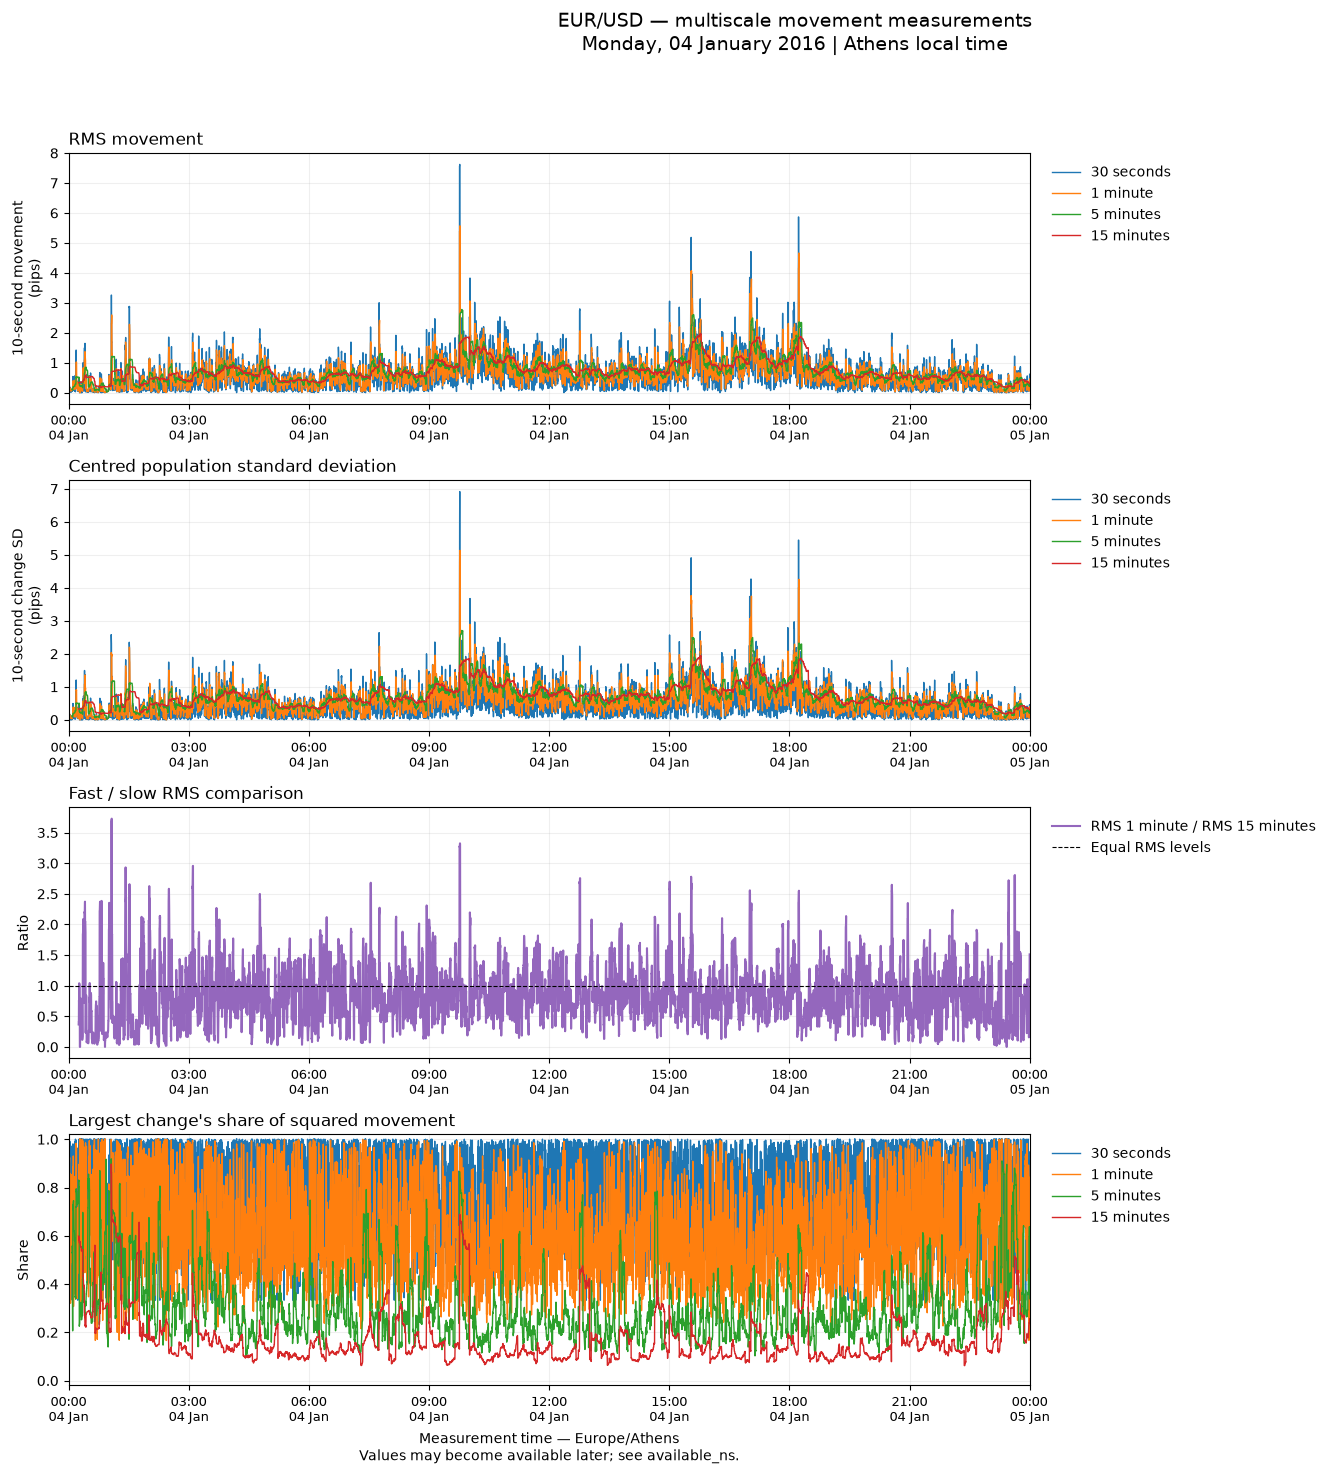

Figure: C:\Users\Ijzd4\Desktop\Inventory-Aware FX Pricing and Hedging Simulator\reports\figures\volatility\volatility_03_v1\first_day_multiscale_volatility.png


In [13]:
# First-day visual review.
# Show every lookback with consistent colours and clear Athens-time labels.
# The horizontal axis is measurement time; publication can be later.

first_file = (
    CTX["run"] /
    f"{RESULT['completed'][0]['summary']['year_month']}.parquet"
)

first_day = pd.Timestamp(
    CTX["inputs"][0]["first_ns"], unit="ns", tz="UTC"
).tz_convert("Europe/Athens").normalize()
next_day = first_day + pd.DateOffset(days=1)

with duckdb.connect() as plot_con:
    plot_con.read_parquet(
        str(first_file), hive_partitioning=False
    ).create_view("plot_source")

    plot_data = v03.frame(plot_con, f"""
        SELECT *
        FROM plot_source
        WHERE sample_ns >= {int(first_day.value)}
          AND sample_ns <= {int(next_day.value)}
        ORDER BY sample_ns
    """)

times = pd.to_datetime(
    plot_data["sample_ns"].astype("Int64"),
    unit="ns", utc=True,
).dt.tz_convert("Europe/Athens")

colours = {
    "30s": "tab:blue",
    "1m": "tab:orange",
    "5m": "tab:green",
    "15m": "tab:red",
}
labels = {
    "30s": "30 seconds",
    "1m": "1 minute",
    "5m": "5 minutes",
    "15m": "15 minutes",
}

fig, axes = plt.subplots(4, 1, figsize=(16, 15), sharex=True)

for key in v03.WINDOWS:
    axes[0].plot(
        times,
        plot_data[f"rms_{key}_pips"].to_numpy(
            dtype=float, na_value=np.nan
        ),
        color=colours[key],
        label=labels[key],
        linewidth=1,
    )
    axes[1].plot(
        times,
        plot_data[f"sd_{key}_pips"].to_numpy(
            dtype=float, na_value=np.nan
        ),
        color=colours[key],
        label=labels[key],
        linewidth=1,
    )
    axes[3].plot(
        times,
        plot_data[f"shock_share_{key}"].to_numpy(
            dtype=float, na_value=np.nan
        ),
        color=colours[key],
        label=labels[key],
        linewidth=1,
    )

axes[2].plot(
    times,
    plot_data["rms_ratio_1m_15m"].to_numpy(
        dtype=float, na_value=np.nan
    ),
    color="tab:purple",
    label="RMS 1 minute / RMS 15 minutes",
)
axes[2].axhline(
    1, color="black", linestyle="--", linewidth=0.8,
    label="Equal RMS levels",
)

axes[0].set_title("RMS movement", loc="left")
axes[0].set_ylabel("10-second movement\n(pips)")
axes[1].set_title("Centred population standard deviation", loc="left")
axes[1].set_ylabel("10-second change SD\n(pips)")
axes[2].set_title("Fast / slow RMS comparison", loc="left")
axes[2].set_ylabel("Ratio")
axes[3].set_title("Largest change's share of squared movement", loc="left")
axes[3].set_ylabel("Share")
axes[3].set_ylim(-0.02, 1.02)

for ax in axes:
    ax.set_xlim(
        first_day.to_pydatetime(),
        next_day.to_pydatetime(),
    )
    ax.xaxis.set_major_locator(
        mdates.HourLocator(
            byhour=list(range(0, 24, 3)),
            tz=first_day.tzinfo,
        )
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter(
            "%H:%M\n%d %b", tz=first_day.tzinfo
        )
    )
    ax.tick_params(axis="x", labelbottom=True, labelsize=9)
    ax.grid(True, alpha=0.2)
    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.01, 1),
        frameon=False,
    )

axes[-1].set_xlabel(
    "Measurement time — Europe/Athens\n"
    "Values may become available later; see available_ns."
)
fig.suptitle(
    "EUR/USD — multiscale movement measurements\n"
    + first_day.strftime("%A, %d %B %Y")
    + " | Athens local time",
    fontsize=14,
)
fig.tight_layout(rect=(0, 0, 0.84, 0.95))

figure_path = CTX["figures"] / "first_day_multiscale_volatility.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()

print("Figure:", figure_path)

In [14]:
# Final status.
# Reports were refreshed by the processing call.
# Prefix processing is not reported as completed full-history processing.

saved_summary = json.loads(
    (CTX["tables"] / "execution_summary.json").read_text(
        encoding="utf-8"
    )
)

assert saved_summary["fingerprint"] == CTX["fingerprint"]
assert saved_summary["machine_checks_passed"]
assert saved_summary["nonzero_machine_checks"] == 0

print("NOTEBOOK_03_EXECUTION_SUMMARY")
print(json.dumps(saved_summary, indent=2))
print("\nReports:", CTX["tables"])
print("Figure:", figure_path)
print("\nSTOP HERE: tell me 'Notebook 03 outputs ready' for direct review.")

NOTEBOOK_03_EXECUTION_SUMMARY
{
  "notebook": "03_multiscale_volatility.ipynb",
  "run_id": "volatility_03_v1",
  "fingerprint": "23cd20f31245e3dd1ff03f508c7f3cd978d581ac41838901cd18a062207499ad",
  "source_run": "sampling_02_v1",
  "source_fingerprint": "ad5235dc14f854d9f26ef04dd2c1fdf846faf05cff43eb9f84afccc229628e54",
  "mode": "prefix_review",
  "available_input_months": 130,
  "processed_months": 1,
  "processed_through": "2016-01",
  "full_history_complete": false,
  "new_months_processed_this_call": 1,
  "processed_sample_rows": 241919,
  "priced_rows": 172790,
  "missing_price_rows": 69129,
  "valid_change_rows": 172786,
  "restart_rows": 4,
  "ready_rows_by_window": {
    "30s": 172778,
    "1m": 172766,
    "5m": 172670,
    "15m": 172430
  },
  "ratio_defined_rows": 172430,
  "max_publication_delay_seconds": 299.772000001,
  "nonzero_machine_checks": 0,
  "synthetic_checks_passed": true,
  "machine_checks_passed": true,
  "human_review": "pending",
  "processing_call_minutes

In [16]:
# Run Notebook 03 over the full available history.
# Reuse completed months and preserve the reviewed January output.
# Refresh reports automatically.
# Human review of the full-history results remains pending.

from pathlib import Path
import importlib.util
import hashlib
import json
import sys

full_root = None
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (
        candidate
        / "functions"
        / "volatility"
        / "multiscale_volatility.py"
    ).is_file():
        full_root = candidate.resolve()
        break

assert full_root is not None, "Run this cell inside the project repository."
sys.path.insert(0, str(full_root))

full_helper = (
    full_root
    / "functions"
    / "volatility"
    / "multiscale_volatility.py"
)
full_spec = importlib.util.spec_from_file_location(
    "fx_volatility_03_full_history",
    full_helper,
)
volatility_module = importlib.util.module_from_spec(full_spec)
full_spec.loader.exec_module(volatility_module)

full_context = volatility_module.prepare(
    root=full_root,
    run_id="volatility_03_v1",
    stop_after_month=None,
    memory="2GB",
    threads=2,
    spill_limit="20GB",
)

reviewed_fingerprint = (
    "23cd20f31245e3dd1ff03f508c7f3cd978d581ac41838901cd18a062207499ad"
)
assert full_context["fingerprint"] == reviewed_fingerprint
assert len(full_context["inputs"]) == 130
assert len(full_context["target"]) == 130

january_checkpoint = (
    full_context["run"] / "_checkpoints" / "2016-01.json"
)
january_output = full_context["run"] / "2016-01.parquet"

assert january_checkpoint.is_file()
assert january_output.is_file()

january_checkpoint_before = hashlib.sha256(
    january_checkpoint.read_bytes()
).hexdigest()
january_output_before = volatility_module.file_info(january_output)

print("Processing all 130 months.")
print("January will resume from its existing checkpoint.")

full_result = volatility_module.process(full_context)
full_summary = full_result["summary"]

full_history_checks = {
    "all_130_months_processed": (
        full_summary["processed_months"] == 130
        and full_summary["full_history_complete"]
        and full_summary["mode"] == "full_history"
    ),
    "processed_through_2026_10": (
        full_summary["processed_through"] == "2026-10"
    ),
    "all_sample_rows_preserved": (
        full_summary["processed_sample_rows"]
        == full_context["source_summary"]["sample_rows"]
        == 34_032_599
    ),
    "all_priced_rows_preserved": (
        full_summary["priced_rows"]
        == full_context["source_summary"]["sample_rows_with_prices"]
    ),
    "price_and_missing_rows_reconcile": (
        full_summary["priced_rows"]
        + full_summary["missing_price_rows"]
        == full_summary["processed_sample_rows"]
    ),
    "changes_and_restarts_reconcile": (
        full_summary["valid_change_rows"]
        + full_summary["restart_rows"]
        == full_summary["priced_rows"]
    ),
    "all_monthly_checks_zero": bool(
        full_result["checks"]
        .drop(columns="year_month")
        .eq(0)
        .all()
        .all()
    ),
    "january_checkpoint_unchanged": (
        hashlib.sha256(january_checkpoint.read_bytes()).hexdigest()
        == january_checkpoint_before
    ),
    "january_output_unchanged": (
        volatility_module.file_info(january_output)
        == january_output_before
    ),
}

failed_checks = [
    name for name, passed in full_history_checks.items()
    if not passed
]
assert not failed_checks, f"Full-history checks failed: {failed_checks}"

completion_report = {
    "run_id": full_context["run_id"],
    "fingerprint": full_context["fingerprint"],
    "checks": full_history_checks,
    "machine_checks_passed": True,
    "human_review": "pending",
}

completion_path = (
    full_context["tables"] / "full_history_completion_checks.json"
)
temporary_path = completion_path.with_suffix(".tmp")
temporary_path.write_text(
    json.dumps(completion_report, indent=2, allow_nan=False),
    encoding="utf-8",
)
temporary_path.replace(completion_path)

print("\nNOTEBOOK_03_EXECUTION_SUMMARY")
print(json.dumps(full_summary, indent=2))
print("\nFULL_HISTORY_COMPLETION_CHECKS_PASSED")
print("\nAnnual summary:")
print(full_result["annual"].to_string(index=False))
print("\nReports:", full_context["tables"])
print("\nTell me 'full-history volatility outputs ready' for direct review.")

Processing all 130 months.
January will resume from its existing checkpoint.
2016-01 resumed
2016-02 rows=250,560 ready 30s=181,418 ready 15m=180,983
2016-03 rows=267,480 ready 30s=198,687 ready 15m=198,339
2016-04 rows=259,200 ready 30s=181,408 ready 15m=181,060
2016-05 rows=267,840 ready 30s=190,052 ready 15m=189,617
2016-06 rows=259,200 ready 30s=190,053 ready 15m=189,705
2016-07 rows=267,840 ready 30s=181,390 ready 15m=181,042
2016-08 rows=267,840 ready 30s=198,691 ready 15m=198,256
2016-09 rows=259,200 ready 30s=190,057 ready 15m=189,709
2016-10 rows=268,200 ready 30s=181,776 ready 15m=181,341
2016-11 rows=259,200 ready 30s=189,694 ready 15m=189,346
2016-12 rows=267,840 ready 30s=189,870 ready 15m=189,261
2017-01 rows=267,840 ready 30s=189,899 ready 15m=189,116
2017-02 rows=241,920 ready 30s=172,782 ready 15m=172,434
2017-03 rows=267,480 ready 30s=198,700 ready 15m=198,352
2017-04 rows=259,200 ready 30s=172,757 ready 15m=172,409
2017-05 rows=267,840 ready 30s=198,692 ready 15m=198